In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
df = pd.read_csv("FOIA_7a_FY2010_FY2019_asof_260930.csv")

/var/folders/kl/1mbq_bq901b23w9l67rfnn0c0000gn/T/ipykernel_16325/679571122.py:1: DtypeWarning: Columns (0: BankZip) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("FOIA_7a_FY2010_FY2019_asof_260930.csv")


In [4]:
df.head()

,AsOfDate,Program,LocationID,BorrName,BorrStreet,BorrCity,BorrState,BorrZip,BankName,BankFDICNumber,...,BusinessType,BusinessAge,LoanStatus,PaidInFullDate,ChargeOffDate,GrossChargeOffAmount,RevolverStatus,JobsSupported,CollateralInd,SoldSecMrktInd
0,2026-09-30,7A,12096.0,"United Renal Associates of Georgia, P.C.","5669 Peachtree Dunwoody Road NE, Suite 240",Atlanta,GA,30342,Wells Fargo Bank National Association,3511.0,...,CORPORATION,"New, Less than 1 Year old",P I F,2010-11-30,NaN,0.0,Y,6.0,N,NaN
1,2026-09-30,7A,89255.0,Sylvia H. Caruso,"5 BROADWAY, SUITE 104",SAUGUS,MA,1906,TruNorth Bank,26484.0,...,INDIVIDUAL,"Existing, 5 or more years",P I F,2013-11-30,NaN,0.0,N,1.0,Y,NaN
2,2026-09-30,7A,29760.0,Bangor Wine & Cheese,436 State Street.,Bangor,ME,4401,Machias Savings Bank,19531.0,...,CORPORATION,Less than 4 years old but at least 3,P I F,2015-11-30,NaN,0.0,N,3.0,Y,NaN
3,2026-09-30,7A,44449.0,Brainy Bunch Learning Center dba Kiddie Academ...,301 Wartman Road,COLLEGEVILLE,PA,19426,"PNC Bank, National Association",6384.0,...,CORPORATION,"Startup, Loan Funds will Open Business",P I F,2018-05-31,NaN,0.0,N,25.0,Y,NaN
4,2026-09-30,7A,507814.0,ON SITE AUTOMOTIVE APPEARANCE SPECIALIST,603 WOODBRIDGE COURT,MIDDLEBURY,IN,46540,"VelocitySBA, LLC",NaN,...,INDIVIDUAL,"Startup, Loan Funds will Open Business",P I F,2013-02-28,NaN,0.0,N,2.0,N,Y


In [5]:
df.shape

(545751, 42)

In [6]:
overview = pd.DataFrame({
    "dtype": df.dtypes,
    "n_unique": df.nunique(),
    "missing_%": (df.isna().mean() * 100).round(1),
})
overview

,dtype,n_unique,missing_%
AsOfDate,str,1,0.0
Program,str,1,0.0
LocationID,float64,3111,0.0
BorrName,str,433982,0.0
BorrStreet,str,472659,0.0
BorrCity,str,26418,0.0
BorrState,str,58,0.0
BorrZip,int64,24035,0.0
BankName,str,2853,0.0
BankFDICNumber,float64,2431,7.2


In [7]:
for col in ["AsOfDate", "Program"]:
    print(df[col].value_counts(dropna=False), "\n")

AsOfDate
2026-09-30    545751
Name: count, dtype: int64 

Program
7A    545751
Name: count, dtype: int64 



In [8]:
df = df.drop(columns=["AsOfDate", "Program"])

<Axes: xlabel='LocationID'>

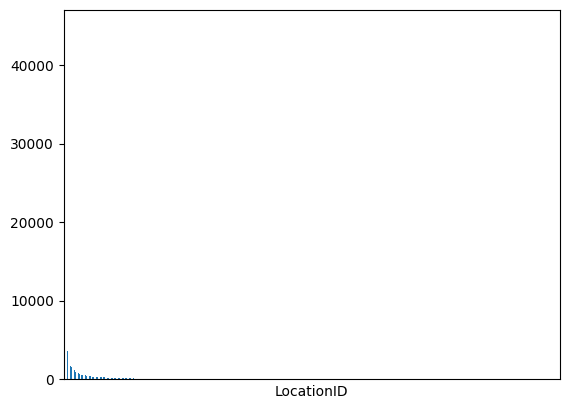

In [9]:
df["LocationID"].value_counts().plot.bar(xticks = [])

Very right-skewed distribution, so we plot only the top K ones

<Axes: xlabel='LocationID'>

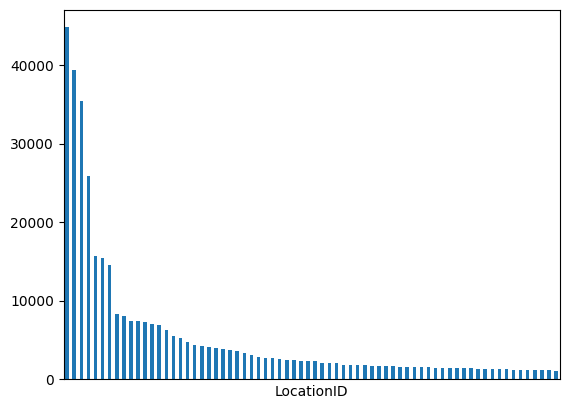

In [10]:
df["LocationID"].value_counts()[:70].plot.bar(xticks = [])

10%: 2 lenders
20%: 3 lenders
30%: 6 lenders
40%: 11 lenders
50%: 20 lenders
60%: 39 lenders
70%: 78 lenders
80%: 171 lenders
90%: 410 lenders
100%: 3111 lenders


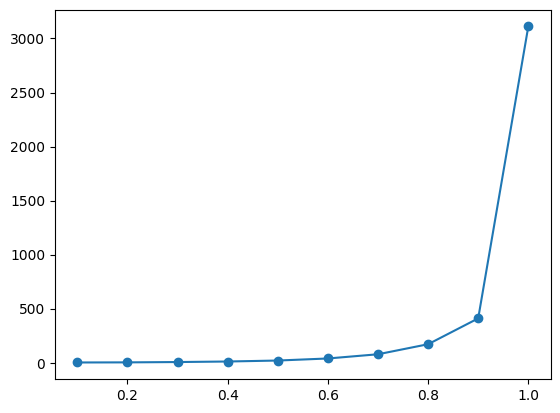

In [11]:
share_lenders = df["LocationID"].value_counts().cumsum() / df["LocationID"].value_counts().sum()

thresholds = [i/10 for i in range(1,11)]
l=[]
for t in thresholds:
    k = (share_lenders < t).sum() + 1 # n of lenders needed to reach threshold pct
    l.append(k)

for t, k in zip(thresholds, l):
    print(f"{t:.0%}: {k} lenders")
    
plt.plot(thresholds, l, marker="o")

From this graph and table we can see that 90% of loans are issued only by 410 lenders, while for example 50% is issued by the top 20 lenders

So, clearly there are banks that lend way more often than others

Can be used in managerial implications

In [12]:
df[["BorrName", "BorrStreet"]].nunique()

BorrName      433982
BorrStreet    472659
dtype: int64

BorrName and BorrStreet are just identifiers, we don't need them at all, so drop them

In [13]:
df[["BorrCity", "BorrZip"]].nunique()

BorrCity    26418
BorrZip     24035
dtype: int64

Same for BorrCity and BorrZip, they are too fine-grained, so there are too many distinct values

In [14]:
df["BorrState"].nunique()

58

<Axes: xlabel='BorrState'>

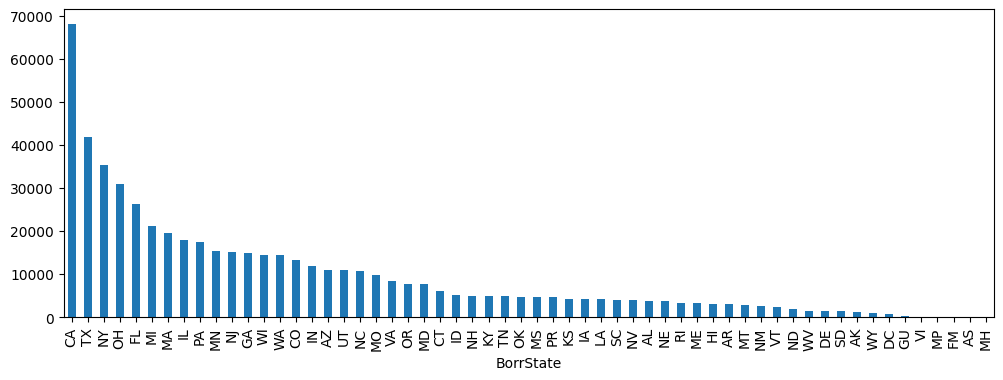

In [15]:
df["BorrState"].value_counts().plot.bar(figsize = (12,4))

We can keep BorrState because there are 58 states (categories) which the models can handle

In [17]:
df["BankName"].nunique()

2853

In [18]:
df[["BankName", "BankStreet", "BankCity", "BankZip", "BankState"]].nunique()

BankName      2853
BankStreet    3012
BankCity      2136
BankZip       3672
BankState       55
dtype: int64

All these information are useless because they identify the bank, so we drop them

In [19]:
df["BankFDICNumber"].value_counts()

BankFDICNumber
3511.0     44763
6560.0     39297
628.0      35386
6548.0     25865
6384.0     15686
           ...  
17478.0        1
10446.0        1
11785.0        1
16635.0        1
11492.0        1
Name: count, Length: 2431, dtype: int64

In [20]:
df["BankNCUANumber"].value_counts()

BankNCUANumber
24692.0    1261
24694.0     902
67190.0     759
24563.0     472
68730.0     446
           ... 
12890.0       1
12765.0       1
10257.0       1
20007.0       1
16626.0       1
Name: count, Length: 452, dtype: int64

BankFDICNumber is the ID of the lender if it is part of the Federal Deposit Insurance Corporation (FDIC), so it is a commercial bank

BankNCUANumber is the ID of the lender if it is part of the Naional Credit Union Administration (NCUA), so it is a credit union

We can use these to create a new variable called: "LenderType", which does not use the specific ID of each lender but simply, the presence of the ID

df["LenderType"] = "Non-bank" # if both the cols are NA (lender is neither a commercial bank nor a trade union)

df.loc[df.BankNCUANumber.notna(), "LenderType"] = "Credit union" # if BankNCUANumber is not NA

df.loc[df.BankFDICNumber.notna(), "LenderType"] = "Bank" # if BankFDICNumber is not NA

Then check the distribution of LenderType

In [21]:
df["GrossApproval"].describe().round(2)

count     545751.00
mean      377395.86
std       672285.50
min         1000.00
25%        40000.00
50%       125000.00
75%       360000.00
max      5000000.00
Name: GrossApproval, dtype: float64

Very right-skewed, so we should use log-scale for graphs eventually

In [25]:
np.corrcoef(df["GrossApproval"], df["SBAGuaranteedApproval"])[1,0]

np.float64(0.9959746683396887)

GrossApproval and SBAGuaranteedApproval have a correlation coefficient of 0.996, clearly because the guaranteed part is a function of the Gross, based on the type of loan (loans of 50k will always get like 85% coverage for example)

So we convert SBAGuaranteedApproval to the percentage instead of the number, then we drop it

df["GuaranteedPct"] = df["SBAGuaranteedApproval"] / df["GrossApproval"]

In [30]:
df["ApprovalDate"] = pd.to_datetime(df["ApprovalDate"])
df["ApprovalFQ"] = (df["ApprovalDate"].dt.month - 10) % 12 // 3 + 1   # Q1 = ott–dic

We set ApprovalDate to the date type, we will use it later for target construction then drop it

We create a new variable ApprovalFQ, that flags the Financial Quarter in which the loan was approved

And we also keep ApprovalFY (Fiscal Year)

Then we drop FirstDisbursementDate that only tells us when the first installment was paid but it has no predictive power

In [34]:
df["ProcessingMethod"].value_counts(normalize=True)

ProcessingMethod
SBA Express Program                          0.481624
Preferred Lenders Program                    0.321929
7a General                                   0.076403
Small Loan Advantage Initiative              0.057759
Patriot Express Loans                        0.011447
Community Advantage Initiative               0.010725
Community Express                            0.010019
Working Capital CAPLine                      0.005873
Rural Loan Initiative                        0.005673
Certified Lenders Program                    0.004861
Gulf Opportunity Pilot Loan Program          0.003152
International Trade Loans                    0.002803
Export Express                               0.002600
7a with EWCP                                 0.001836
Preferred Lenders with EWCP                  0.001206
Contract CAPLine                             0.001048
Seasonal CAPLine                             0.000405
Builders CAPLine                             0.000282
Dealer Floo

In [36]:
channel_groups = {
    "SBA Express Program": "Express", "SBA Express Bridge Loan": "Express",
    "Preferred Lenders Program": "Delegated", "Certified Lenders Program": "Delegated",
    "7a General": "Standard",
    "Small Loan Advantage Initiative": "Small-loan", "Rural Loan Initiative": "Small-loan",
    "Community Express": "Mission", "Community Advantage Initiative": "Mission",
    "Community Advantage International Trade": "Mission",
    "Patriot Express Loans": "Mission", "Gulf Opportunity Pilot Loan Program": "Mission",
    "Working Capital CAPLine": "Specialty", "Contract CAPLine": "Specialty",
    "Seasonal CAPLine": "Specialty", "Builders CAPLine": "Specialty",
    "Small Asset Base Line of Credit (CAPLine)": "Specialty",
    "Export Express": "Specialty", "International Trade Loans": "Specialty",
    "7a with EWCP": "Specialty", "Preferred Lenders with EWCP": "Specialty",
    "Certified Lenders Program with EWCP": "Specialty",
    "Dealer Floor Plan Loans": "Specialty", "Export Import Harmonization  (EXIM)": "Specialty",
}
df["ChannelGroup"] = df["ProcessingMethod"].map(channel_groups)
assert df["ChannelGroup"].notna().all(), df.loc[df["ChannelGroup"].isna(), "ProcessingMethod"].unique()

Group channels per similarity, then drop ProcessingMethod

Keep InitialInterestRate and FixedorVariableInterestInd

We have to drop TermInMonths because only few observationz of charged-off loans (LoanStatus == CHGOFF) have a term that is a multiple of 12, meaning after default the field is overwritten with the elapsed months. This could tell the model that systematically, if a duration is not a multiple of 12, then it will default, which is leakage.

In [53]:
df["NaicsSector"] = df["NaicsCode"].astype(str).str[:2]
sector_names = {
    "11": "Agriculture", "21": "Mining", "22": "Utilities", "23": "Construction",
    "31": "Manufacturing", "32": "Manufacturing", "33": "Manufacturing",
    "42": "Wholesale", "44": "Retail", "45": "Retail",
    "48": "Transportation", "49": "Transportation", "51": "Information",
    "52": "Finance & Insurance", "53": "Real Estate", "54": "Professional Services",
    "55": "Management of Companies", "56": "Admin & Support", "61": "Education",
    "62": "Health Care", "71": "Arts & Recreation", "72": "Accommodation & Food",
    "81": "Other Services", "92": "Public Administration",
}
df["Sector"] = df["NaicsCode"].astype(str).str[:2].map(sector_names)
df["Sector"] = df["Sector"].fillna("Other Services")
df["Sector"].value_counts()

Sector
Retail                     75230
Accommodation & Food       71306
Construction               56907
Professional Services      54033
Health Care                51602
Other Services             48949
Manufacturing              43233
Wholesale                  28634
Transportation             28571
Admin & Support            24943
Arts & Recreation          16028
Real Estate                12053
Finance & Insurance         9132
Agriculture                 8632
Education                   7558
Information                 6478
Mining                      1552
Utilities                    465
Management of Companies      351
Public Administration         94
Name: count, dtype: int64

We use the first 2 digits of the NaicsCode to encode categories for Sector, then drop NaicsCode

We drop NaicsDescription

In [54]:
df["IsFranchise"] = df["FranchiseCode"].notna().astype(int)

FranchiseCode and FranchiseName are almost entirely null, so we just flag the not-null ones as IsFranchise

In [55]:
(df.BorrState == df.ProjectState).mean() * 100

np.float64(99.81108600808794)

We drop ProjectCounty because too many distinct values and does not really add much

We also drop ProjectState because it is 99.8% equal to BorrState which we already keep

Same issues with SBADistrictOffice and CongressionalDistrict

In [56]:
df["BusinessType"].value_counts(normalize=True)

BusinessType
CORPORATION    0.873013
INDIVIDUAL     0.108272
PARTNERSHIP    0.018715
Name: proportion, dtype: float64

In [57]:
df["BusinessType"].isnull().sum()

np.int64(32)

In [58]:
df["BusinessType"] = df["BusinessType"].fillna("CORPORATION")

BusinessType we keep it absolutely, and the 32 null values we put them in CORPORATION which is the majority, does not make much difference

In [61]:
age_groups = {
    "Startup, Loan Funds will Open Business": "Startup",
    "New, Less than 1 Year old": "New (<2y)",
    "New Business or 2 years or less": "New (<2y)",
    "Less than 3 years old but at least 2": "Existing (2y+)",
    "Less than 4 years old but at least 3": "Existing (2y+)",
    "Less than 5 years old but at least 4": "Existing (2y+)",
    "Existing, 5 or more years": "Existing (2y+)",
    "Existing or more than 2 years old": "Existing (2y+)",
    "Change of Ownership": "Existing (2y+)",
    "Unanswered": "Unknown",
}
df["BusinessAgeNew"] = df["BusinessAge"].map(age_groups).fillna("Unknown")

In [62]:
df["BusinessAgeNew"].value_counts(normalize=True)

BusinessAgeNew
Existing (2y+)    0.662234
Startup           0.149740
New (<2y)         0.096797
Unknown           0.091228
Name: proportion, dtype: float64

Due to a change in recording BusinessAge in 2018, we put everything into 4 groups (startup is yet to open) so now everything is consistent

## Target Creation

In [ ]:
df["LoanStatus"] = df["LoanStatus"].str.replace(" ", "")   # "P I F" -> "PIF"
df = df[df["LoanStatus"].isin(["PIF", "CHGOFF", "EXEMPT"])]  # CANCLD (66.746) and COMMIT (42) go away

In [ ]:
approval = pd.to_datetime(df["ApprovalDate"])
chargeoff = pd.to_datetime(df["ChargeOffDate"])
df["Default"] = ((df["LoanStatus"] == "CHGOFF") &
                 (chargeoff <= approval + pd.DateOffset(years=7))).astype(int)
df["Default"].value_counts()

Here we create the target using a fixed 7-year observation window for every loan. Seven years is the maximum we can use: the last loans were approved in September 2019 and the data snapshot is from September 2026.

Meaning, if a loan was created in 2010 and was charged off by 2017 (within 7 years of approval), it is labelled as a default (Default = 1). If it was paid in full, is still active, or was charged off only after 2017, it is labelled Default = 0, because it did not default within its first 7 years.

This way every loan, from FY2010 to FY2019, gets the same 7-year window to default. Older loans don't look riskier just because we have observed them for longer, and every label is known with certainty, including for loans that are still active (EXEMPT).

Then we drop LoanStatus, ChargeOffDate, PaidInFullDate, GrossChargeOffAmount, ApprovalDate because are all leakage

In [ ]:
df["IsRevolver"] = (df["RevolverStatus"] == "Y").astype(int)
df["HasCollateral"] = (df["CollateralInd"] == "Y").astype(int)

Here we create the flag IsRevolver to indicate if the loan was a term loan or a revolving line of credit

Also the flag HasCollateral if the SBA lender reported that the loan was backed by collateral

JobsSupported and SoldSecMrktInd we drop because not meaningful